<a target="_blank" href="https://storage.googleapis.com/weathernext-public/colabs/SatWeave_Starter_Guide_Zarr_on_Google_Cloud_Storage.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Exploring Global Multi-Spectral Satellite Mosaics with Zarr on Google Cloud Storage and SatWeave

**Welcome!** This section demonstrates how to load, slice, and visualize the **SatWeave** dataset available in Zarr format on Google Cloud Storage, developed by Google DeepMind and Google Research.

**Dataset Overview**

SatWeave is a global, analysis-ready dataset of multi-spectral geostationary satellite observations that harmonizes imagery from **five operational geostationary satellite positions** (**GOES-East**, **GOES-West**, **Meteosat Prime 0°**, **Meteosat Indian Ocean (IODC)**, and **Himawari**) into a single global mosaic across **17 spectral bands**:
* **7 Visible, Near-IR & SWIR Reflectance Bands:** `0 to 100 %`
* **10 Shortwave, Water Vapor & Thermal IR Brightness Temperature Bands:** `K`

SatWeave provides:
* **Near-Real-Time Stream & Archive (`2026 to present`):** Updated **every hour** at **0.1° (~10 km)** resolution with **~1 hour latency** (24 timesteps/day).
* **Historical Archive (`2016–2025`):** Continuous multi-year record at **30-minute intervals** (`2016-01-01T00:00:00` to `2025-12-31T23:30:00` UTC, 48 timesteps/day).

SatWeave provides the live satellite observations used to initialize WeatherNext 3 every hour and to generate near-real-time precipitation estimates in PARDIG-NRT.

**Notebook Purpose**

This section aims to:

* Familiarize users with the structure, 17 spectral channels, and coordinate conventions of SatWeave in Zarr on Google Cloud Storage.
* Demonstrate how to query and slice multi-spectral satellite channels using Xarray and obstore.
* Showcase practical meteorological applications, including tropical cyclone cloud-top brightness temperature analysis, multi-spectral visible vs. water vapor vs. IR comparisons, and global interactive Folium mapping.

**Copyright & Attribution Information**

Copyright 2026 Google LLC. All materials and data are licensed under the [Creative Commons Attribution 4.0 International License (CC-BY 4.0)](https://creativecommons.org/licenses/by/4.0/). Publicly accessible with any Google Cloud account (no access request form required).

> **Attribution Notice:**
> © 2026 Google LLC's machine learning models and data processing pipelines used to create the experimental data made available under CC BY 4.0 license terms. This data is intended for experimental modeling only and is not intended, validated, or approved for real-world operational warning use.

**Additional Documentation**

* [SatWeave Developer Guide](https://developers.google.com/weathernext/guides/satweave)
* [Xarray Library Documentation](https://docs.xarray.dev)

# SatWeave Dataset Schema & Cloud Storage Structure

SatWeave Zarr datasets are published in Google Cloud Storage under:
`gs://satweave_1/`

### Directory Structure & Storage Paths

```none
gs://satweave_1/
└── zarr/
    ├── 2016_to_2025/
    │   └── mosaic.zarr                    # Historical archive (2016-01-01 to 2025-12-31 UTC · 30-min cadence)
    └── 2026_to_present/                   # Live operational mosaics (~1 hour latency)
        ├── <YYYYMMDDTHHMMSS>/
        │   └── mosaic.zarr                # Single hourly mosaic · 1h cadence · (1, 1801, 3600)
        └── ...
```

### Dimensions & Coordinates

<div class="inline-table">

| Coordinate / Dimension | Shape & Type | Description |
| --- | --- | --- |
| `time` | `datetime64[ns]` | Observation valid timestamp (UTC, 30-min intervals in `2016_to_2025/`; 1-hour intervals in `2026_to_present/`). |
| `latitude` | `1801` (`float64`) | Global 0.1° grid ordered north-to-south from `90.0°` to `-90.0°` (`degrees_north`). |
| `longitude` | `3600` (`float64`) | Global 0.1° grid in **0° to 360° convention** (`0.0°` to `359.9°`). Convert standard `-180°..180°` using `lon % 360`. |

</div>

### Supported 17 Spectral Bands

<div class="inline-table">

| Variable Name | Central Wavelength | Channel Type | Units | Physical Application |
| --- | --- | --- | --- | --- |
| `mosaic_470_nm` | 0.47 µm (470 nm) | Blue Visible | % | Aerosols, dust, smoke, daytime clouds |
| `mosaic_509_nm` | 0.51 µm (509 nm) | Green Visible | % | True-color composites, vegetation, aerosols |
| `mosaic_640_nm` | 0.64 µm (640 nm) | Red Visible | % | Daytime clouds, fog, snow & ice discrimination |
| `mosaic_863_nm` | 0.86 µm (863 nm) | Near-IR | % | Vegetation index, land/water contrast |
| `mosaic_1370_nm` | 1.37 µm (1370 nm) | Near-IR | % | Thin high-altitude cirrus cloud detection |
| `mosaic_1610_nm` | 1.61 µm (1610 nm) | SWIR | % | Water vs. ice cloud phase, snow vs. cloud |
| `mosaic_2250_nm` | 2.25 µm (2250 nm) | SWIR | % | Cloud droplet effective radius, hot spots |
| `mosaic_3830_nm` | 3.83 µm (3830 nm) | Shortwave IR | K | Nighttime fog/low clouds, fire & hotspot detection |
| `mosaic_6200_nm` | 6.20 µm (6200 nm) | Upper Water Vapor | K | Upper-tropospheric moisture, jet streams |
| `mosaic_6900_nm` | 6.90 µm (6900 nm) | Mid Water Vapor | K | Mid-tropospheric moisture, atmospheric wind flow |
| `mosaic_7330_nm` | 7.33 µm (7330 nm) | Lower Water Vapor | K | Lower/mid-tropospheric moisture, convection initiation |
| `mosaic_8590_nm` | 8.59 µm (8590 nm) | Cloud-Top Phase IR | K | Ice vs. water cloud phase, volcanic SO₂ |
| `mosaic_9620_nm` | 9.62 µm (9620 nm) | Ozone Absorption IR| K | Total column ozone, stratospheric dynamics |
| `mosaic_10400_nm` | 10.40 µm (10400 nm) | Clean Longwave IR | K | Cloud-top temperature, surface temperature |
| `mosaic_11200_nm` | 11.20 µm (11200 nm) | Standard Longwave IR| K | Deep convection, cloud-top & sea surface temperature |
| `mosaic_12400_nm` | 12.40 µm (12400 nm) | Split-Window IR | K | Low-level moisture, volcanic ash, SST |
| `mosaic_13300_nm` | 13.30 µm (13300 nm) | CO₂ Absorption IR | K | Cloud-top height assignment, air temperature |

</div>

> **Note on Sensor Coverage & Missing Values (`NaN`):**
> * **Geostationary Viewing Limits:** Geostationary coverage extends to approximately `±60°–65°` latitude; polar grid cells beyond the viewing limb are `NaN`.
> * **Nighttime Reflectance:** Solar reflectance channels (`0–100 %`) are `NaN` during local nighttime.
> * **Constellation Band Availability:** 11 bands are carried on all 5 satellites (~85–87% global coverage). Specific channels carried on a subset of sensors (e.g. `mosaic_509_nm` on Himawari only; `mosaic_1370_nm` on GOES only; `mosaic_470_nm`, `mosaic_2250_nm`, `mosaic_6900_nm`, `mosaic_10400_nm` on GOES and Himawari) contain `NaN` outside their respective satellite coverage sectors.

## Import Python Libraries & Setup


In [ ]:
!pip install zarr obstore


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 15.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [zarr]


In [ ]:
from google.colab import auth
import folium
from ipyleaflet import basemaps, basemap_to_tiles
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
import obstore
from scipy import interpolate as scipy_interpolate
import xarray as xr
import zarr

import warnings
# Suppress FutureWarning
warnings.filterwarnings("ignore", category=FutureWarning)


# SatWeave Example Queries

First, open the multi-spectral SatWeave Zarr dataset from Google Cloud Storage using `obstore` and `xarray`.

In [ ]:
# Open an hourly SatWeave Zarr store on Google Cloud Storage

auth.authenticate_user()

gcs_satweave = obstore.store.GCSStore(
    bucket="satweave_1",
    prefix="zarr/2026_to_present/20261001T120000/mosaic.zarr",
)

satweave_store = zarr.storage.ObjectStore(gcs_satweave)
satweave_ds = xr.open_zarr(satweave_store, chunks={})

satweave_ds

<xarray.Dataset> Size: 441MB
Dimensions:          (time: 1, latitude: 1801, longitude: 3600)
Coordinates:
  * time             (time) datetime64[ns] 8B 2026-10-01T12:00:00
  * latitude         (latitude) float64 14kB 90.0 89.9 89.8 ... -89.9 -90.0
  * longitude        (longitude) float64 29kB 0.0 0.1 0.2 ... 359.7 359.8 359.9
Data variables: (12/17)
    mosaic_10400_nm  (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_11200_nm  (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_12400_nm  (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_13300_nm  (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_1370_nm   (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_1610_nm   (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    ...               ...
    mosaic_640_nm    (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_6900_nm   (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_7330_nm   (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_8590_nm   (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_863_nm    (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
    mosaic_9620_nm   (time, latitude, longitude) float32 26MB dask.array<chunksize=(1, 1801, 3600), meta=np.ndarray>
Attributes:
    Conventions:              CF-1.8
    title:                    Calibrated Geostationary Satellite Mosaic (Earl...
    institution:              Google Research / Google DeepMind
    source:                   Calibrated geostationary satellite constellatio...
    grid_resolution_degrees:  0.1
    crs:                      EPSG:4326

## Interactive Global Satellite Mosaic Map (`mosaic_3830_nm`)



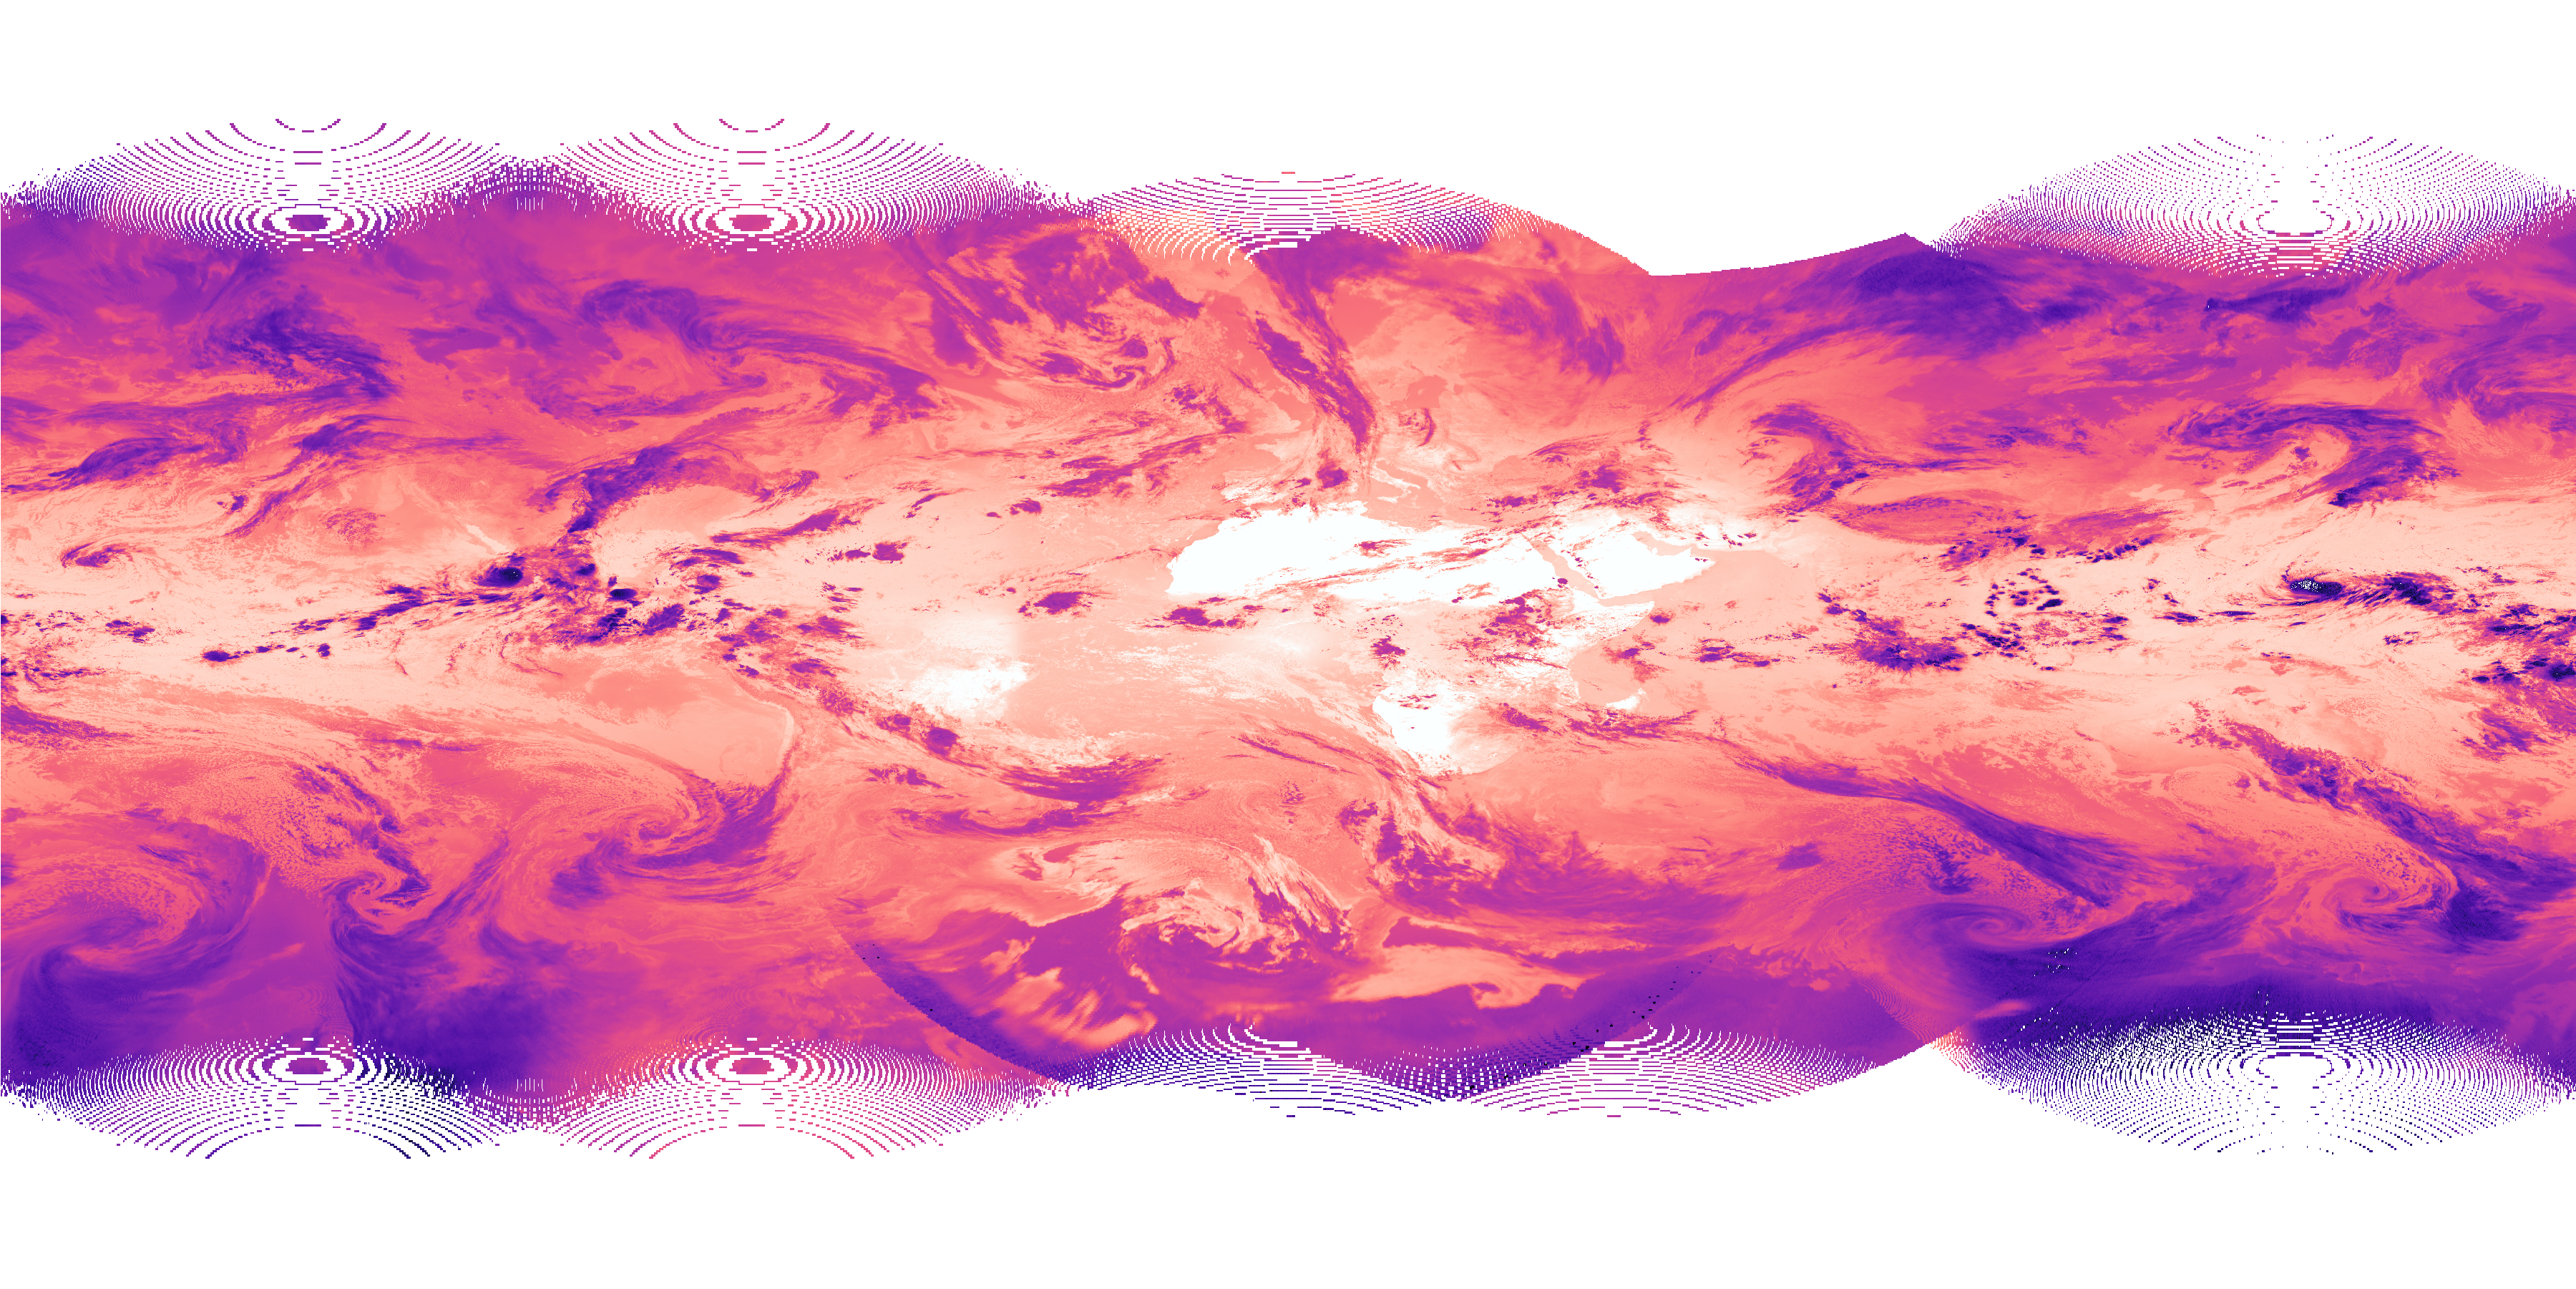

In [ ]:
import folium
import matplotlib
import numpy as np
from scipy import interpolate as scipy_interpolate

global_ir = satweave_ds["mosaic_3830_nm"].isel(time=0).load()

y_dim, x_dim = "latitude", "longitude"

# Flatten coordinates and values
var_flat = global_ir.stack(lat_lon=(y_dim, x_dim))
x = var_flat[x_dim].values
y = var_flat[y_dim].values
z = var_flat.values

# Convert longitudes from [0, 360) to [-180, 180] for Web Mercator mapping
x = np.where(x > 180, x - 360, x)

nx = global_ir.sizes[x_dim]
ny = global_ir.sizes[y_dim]

dx = 360.0 / nx
dy = 180.0 / ny
lon_bins = np.linspace(-180.0 - dx / 2, 180.0 - dx / 2, nx + 1)
lat_bins = np.linspace(-90.0 - dy / 2, 90.0 + dy / 2, ny + 1)

# Bin data onto regular grid
weighted_sum, _, _ = np.histogram2d(x, y, bins=(lon_bins, lat_bins), weights=z)
counts, _, _ = np.histogram2d(x, y, bins=(lon_bins, lat_bins))

with np.errstate(divide="ignore", invalid="ignore"):
    grid = np.where(counts > 0, weighted_sum / counts, np.nan)

# Transpose and flip so row 0 is North (+90) and col 0 is West (-180)
grid_equirectangular = np.flipud(grid.T)

# Reproject equirectangular latitudes to Web Mercator latitudes (EPSG:3857)
max_merc_lat = 85.0511287798
y_merc = np.linspace(np.pi, -np.pi, ny)
lat_target = np.degrees(2 * np.arctan(np.exp(y_merc)) - np.pi / 2)
lat_source = np.linspace(90.0, -90.0, ny)

f_interp = scipy_interpolate.interp1d(
    lat_source,
    grid_equirectangular,
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value=np.nan,
)
grid_mercator = f_interp(lat_target)

# Normalize brightness temperatures (190 K to 310 K) and apply colormap
norm = matplotlib.colors.Normalize(vmin=190.0, vmax=310.0, clip=True)
cm = matplotlib.colormaps["magma"]
rgba_img = cm(norm(grid_mercator))

# Set alpha to 0 for missing values (NaN beyond limb or polar limbs)
rgba_img[np.isnan(grid_mercator), 3] = 0.0
basemap = basemaps.OpenStreetMap
tile_layer = basemap_to_tiles(basemap.DE)

tile_url = tile_layer.url
attribution = tile_layer.attribution
# Create Folium base map
m_sat = folium.Map(
    location=[15, 0],
    zoom_start=2,
    tiles=tile_url,
    attr=attribution
)

# Overlay raster satellite field
folium.raster_layers.ImageOverlay(
    image=rgba_img,
    bounds=[[-max_merc_lat, -180.0], [max_merc_lat, 180.0]],
    mercator_project=False,
    opacity=0.8,
).add_to(m_sat)

# Display interactive map
m_sat